# M3 · Perceptrón Multicapa (`MLPClassifier`)

Tercer modelo de la matriz 3×3 (**P1 / P2 / P3** × **M1 Random Forest / M2 XGBoost / M3 MLP**), sobre el dataset UCI *Estimation of Obesity Levels Based on Eating Habits and Physical Condition* (id 544). El problema es de clasificación multiclase con 7 niveles de peso.

| Sección | Contenido |
|---|---|
| 1 | Configuración |
| 2 | Datos: mismo contrato que `Desarrollo.ipynb` |
| 3 | Preprocesamientos disponibles (P1 y P2) |
| 4 | Modelo M3 y complejidad teórica |
| 5 | Búsqueda de hiperparámetros por preprocesamiento |
| 6 | Control del sobreajuste |
| 7 | Controles: sin `Gender` y benchmark operativo |
| 8 | Evaluación del mejor modelo |
| 9 | Estabilidad ante la semilla |
| 10 | Exportación de modelos y métricas |
| 11 | Conclusiones |

## 1. Configuración

In [1]:
import json
import subprocess
import sys
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

# Instalación automática en Google Colab si falta ucimlrepo
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
    validation_curve,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

# P2 se importa desde el módulo del equipo (no se copia el código).
# Ejecutar desde la raíz del repositorio; en Colab, subir la carpeta src/ junto al cuaderno.
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
try:
    from src.p2_habitos import construir_p2
except ImportError as error:
    raise ImportError(
        "No se encontró src/p2_habitos.py. Ejecuta el cuaderno desde la raíz del repositorio "
        "o, en Colab, crea la carpeta src/ y sube p2_habitos.py e __init__.py.") from error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")

# Semilla para que todo el equipo obtenga los mismos resultados
SEMILLA = 20
np.random.seed(SEMILLA)

import sklearn
print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | semilla = {SEMILLA}")

scikit-learn 1.9.1 | pandas 3.1.1 | semilla = 20


## 2. Datos: mismo contrato que `Desarrollo.ipynb`

Se replican la carga, la codificación, la eliminación de duplicados y la partición 80/20 estratificada, para que M3 se compare con M1 y M2 **sobre las mismas filas**. La justificación de cada decisión está en el EDA.

In [2]:
obesidad = fetch_ucirepo(id=544)
dataset = pd.concat([obesidad.data.features, obesidad.data.targets], axis=1)
dataset["IMC"] = dataset["Weight"] / dataset["Height"] ** 2

data = dataset.copy()

# Binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})
for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})

# Ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
data["CAEC"] = data["CAEC"].map(orden_frecuencia)
data["CALC"] = data["CALC"].replace("Always", "Frequently")   # "Always" tiene 1 solo registro
data["CALC"] = data["CALC"].map(orden_frecuencia)

# Nominales
data["MTRANS"] = data["MTRANS"].replace({"Bike": "Two_Wheels", "Motorbike": "Two_Wheels"})
data = pd.get_dummies(data, columns=["MTRANS"], prefix="MTRANS", dtype=int)

# Target ordinal de 0 a 6
niveles = {
    "Insufficient_Weight": 0, "Normal_Weight": 1, "Overweight_Level_I": 2, "Overweight_Level_II": 3,
    "Obesity_Type_I": 4, "Obesity_Type_II": 5, "Obesity_Type_III": 6,
}
data["NObeyesdad"] = data["NObeyesdad"].map(niveles)
nombres_clases = {v: k for k, v in niveles.items()}

# Duplicados: se eliminan ANTES de dividir
sin_dup = ~dataset.duplicated()
print(f"Duplicados eliminados: {(~sin_dup).sum()} ({len(dataset)} -> {sin_dup.sum()} registros)")
data_u = data[sin_dup]

X_prev = data_u.drop(columns=["NObeyesdad", "Weight", "Height", "IMC"])   # preventivo (principal)
X_oper = data_u.drop(columns=["NObeyesdad"])                              # operativo (referencia)
y = data_u["NObeyesdad"]

idx_train, idx_test = train_test_split(y.index, test_size=0.2, stratify=y, random_state=SEMILLA)
X_train, X_test = X_prev.loc[idx_train], X_prev.loc[idx_test]
X_train_oper, X_test_oper = X_oper.loc[idx_train], X_oper.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

assert not {"NObeyesdad", "Weight", "Height", "IMC"} & set(X_train.columns), "Fuga en el preventivo"
print("Preventivo -> Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Operativo  -> Entrenamiento:", X_train_oper.shape, "| Prueba:", X_test_oper.shape)

Duplicados eliminados: 24 (2111 -> 2087 registros)
Preventivo -> Entrenamiento: (1669, 17) | Prueba: (418, 17)
Operativo  -> Entrenamiento: (1669, 20) | Prueba: (418, 20)


## 3. Preprocesamientos

| | Qué hace | Variables de salida |
|---|---|:---:|
| **P1** | `RobustScaler` (mediana e IQR) sobre las 17 variables | 17 |
| **P2** | 4 variables de hábitos + Yeo-Johnson + `StandardScaler` (`src/p2_habitos.py`) | 21 |
| **P3** | `RobustScaler` + PCA al 95 % de varianza | pendiente de integrar |

Un MLP es muy sensible a la escala y a la forma de las entradas, porque ajusta sus pesos por descenso de gradiente. Por eso el preprocesamiento va **dentro del `Pipeline`**: en cada pliegue de la validación cruzada se ajusta solo con los datos de entrenamiento de ese pliegue.

In [3]:
def crear_preprocesador_p1(X_tr):
    # Misma definición del cuaderno p1-m1-random-forest
    return Pipeline([("scaler", RobustScaler())])


def crear_preprocesador_p2(X_tr):
    return construir_p2(X_tr)


# Cada entrada es una función que recibe X de entrenamiento y devuelve el preprocesador sin ajustar.
preprocesadores = {
    "P1_RobustScaler": crear_preprocesador_p1,
    "P2_Habitos_YeoJohnson": crear_preprocesador_p2,
    # "P3_Robust_PCA95": crear_preprocesador_p3,   # agregar cuando P3 esté en el repositorio
}

## 4. Modelo M3: Perceptrón Multicapa

El MLP es una red densa (*feed-forward*). Cada capa oculta calcula

$$h^{(l)} = \text{ReLU}\left(W^{(l)} h^{(l-1)} + b^{(l)}\right), \qquad \text{ReLU}(z) = \max(0, z)$$

y la capa de salida aplica *softmax* sobre las 7 clases. Los pesos se aprenden minimizando la entropía cruzada con penalización $L_2$ (`alpha`), usando el optimizador **Adam** por mini-lotes.

### Control del sobreajuste
- **Early stopping:** se aparta el 10 % del entrenamiento como validación interna (estratificada). Si la exactitud en ella no mejora durante 30 épocas, el entrenamiento se detiene y se restauran los mejores pesos.
- **Regularización $L_2$** (`alpha`) y **tamaño de la red** (`hidden_layer_sizes`), ajustados por validación cruzada.

### Complejidad computacional teórica (Big-O)
Sea $n$ el número de muestras de entrenamiento, $d$ las variables tras el preprocesamiento, $n_1, \dots, n_L$ las neuronas de cada capa oculta, $c = 7$ las clases, $E$ las épocas ejecutadas y $W$ el número de parámetros:

$$W = \sum_{l=1}^{L+1} \left(n_{l-1} + 1\right) n_l, \qquad n_0 = d,\; n_{L+1} = c$$

| Fase | Complejidad | Explicación |
| :--- | :---: | :--- |
| **Entrenamiento (tiempo)** | $\mathcal{O}(E \cdot n \cdot W)$ | Cada época recorre las $n$ muestras con propagación hacia adelante y hacia atrás. |
| **Inferencia por muestra (tiempo)** | $\mathcal{O}(W)$ | Solo multiplicaciones de matrices de pesos. |
| **Memoria / Espacio** | $\mathcal{O}(W)$ | Pesos y sesgos. Durante el entrenamiento, Adam guarda además dos momentos por parámetro. |

## 5. Búsqueda de hiperparámetros por preprocesamiento

Mismo protocolo que M1: `RandomizedSearchCV` con **30 combinaciones**, validación cruzada estratificada de **5 pliegues** (semilla 20) y **F1-macro**. El conjunto de prueba no participa en la selección.

In [4]:
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

param_dist_mlp = {
    "clf__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64), (256, 128), (128, 64, 32)],
    "clf__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 0.5],
    "clf__learning_rate_init": [1e-3, 3e-3, 1e-2, 3e-2],
    "clf__batch_size": [16, 32, 64, 128],
}


def crear_mlp(semilla=SEMILLA):
    return MLPClassifier(
        activation="relu", solver="adam",
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
        max_iter=1000, random_state=semilla,
    )


def contar_parametros(mlp):
    return int(sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))


def entrenar_evaluar_mlp(nombre_prep, crear_prep, X_tr, y_tr, X_te, y_te, nombre_bench="Preventivo"):
    # Ajusta el MLP con 5-Fold CV sobre un preprocesador y mide métricas y complejidad
    pipe = Pipeline([("prep", crear_prep(X_tr)), ("clf", crear_mlp())])

    busqueda = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_dist_mlp,
        n_iter=30,
        scoring="f1_macro",
        cv=cv_5,
        random_state=SEMILLA,
        n_jobs=-1,
        return_train_score=True,
    )
    busqueda.fit(X_tr, y_tr)

    # Tiempo de entrenamiento del mejor pipeline
    pipe_final = clone(busqueda.best_estimator_)
    t0 = time.perf_counter()
    pipe_final.fit(X_tr, y_tr)
    tiempo_fit_s = time.perf_counter() - t0

    # Latencia de inferencia sobre todo el conjunto de prueba
    t0 = time.perf_counter()
    y_pred_te = pipe_final.predict(X_te)
    latencia_total_ms = (time.perf_counter() - t0) * 1000
    y_pred_tr = pipe_final.predict(X_tr)

    # Tamaño en disco del pipeline completo (.pkl)
    with tempfile.TemporaryDirectory() as carpeta:
        ruta_tmp = Path(carpeta) / "modelo.pkl"
        joblib.dump(pipe_final, ruta_tmp)
        tamano_kb = ruta_tmp.stat().st_size / 1024

    mlp = pipe_final.named_steps["clf"]
    i = busqueda.best_index_
    res = busqueda.cv_results_
    cv_pliegues = np.array([res[f"split{k}_test_score"][i] for k in range(cv_5.get_n_splits())])
    train_acc = accuracy_score(y_tr, y_pred_tr)
    test_acc = accuracy_score(y_te, y_pred_te)

    registro = {
        "Modelo": "M3_MLP",
        "Preprocesamiento": nombre_prep,
        "Benchmark": nombre_bench,
        "CV F1-macro": f"{cv_pliegues.mean():.4f} ± {cv_pliegues.std():.4f}",
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Brecha Train-Test": round(train_acc - test_acc, 4),
        "Test F1-macro": round(f1_score(y_te, y_pred_te, average="macro"), 4),
        "Tiempo fit (s)": round(tiempo_fit_s, 4),
        "Latencia test (ms)": round(latencia_total_ms, 3),
        "ms / muestra": round(latencia_total_ms / len(X_te), 4),
        "Capas ocultas": str(mlp.hidden_layer_sizes),
        "Parámetros (W)": contar_parametros(mlp),
        "Épocas": int(mlp.n_iter_),
        "Tamaño (.pkl KB)": round(tamano_kb, 1),
        "Mejores hiperparámetros": busqueda.best_params_,
    }
    extra = {"cv_media": cv_pliegues.mean(), "cv_pliegues": cv_pliegues}
    return pipe_final, registro, extra

In [5]:
modelos_mlp, resultados_mlp, extras = {}, [], {}

for nombre_p, crear_prep in preprocesadores.items():
    t0 = time.perf_counter()
    modelo, fila, extra = entrenar_evaluar_mlp(nombre_p, crear_prep, X_train, y_train, X_test, y_test)
    modelos_mlp[nombre_p], extras[nombre_p] = modelo, extra
    resultados_mlp.append(fila)
    print(f"{nombre_p}: búsqueda terminada en {time.perf_counter() - t0:,.0f} s")
    print("  Mejores hiperparámetros:", fila["Mejores hiperparámetros"])

tabla_mlp = pd.DataFrame(resultados_mlp)
tabla_mlp.drop(columns=["Mejores hiperparámetros"]).set_index("Preprocesamiento").T

P1_RobustScaler: búsqueda terminada en 407 s
  Mejores hiperparámetros: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (256, 128), 'clf__batch_size': 32, 'clf__alpha': 0.001}


P2_Habitos_YeoJohnson: búsqueda terminada en 493 s
  Mejores hiperparámetros: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (256, 128), 'clf__batch_size': 32, 'clf__alpha': 0.001}


Preprocesamiento,P1_RobustScaler,P2_Habitos_YeoJohnson
Modelo,M3_MLP,M3_MLP
Benchmark,Preventivo,Preventivo
CV F1-macro,0.7421 ± 0.0134,0.7531 ± 0.0027
Train Accuracy,0.927,0.860
Test Accuracy,0.766,0.756
Brecha Train-Test,0.161,0.104
Test F1-macro,0.756,0.752
Tiempo fit (s),28.480,13.846
Latencia test (ms),6.163,24.967
ms / muestra,0.015,0.060


In [6]:
# El preprocesamiento ganador se elige por validación cruzada, NO por el conjunto de prueba
MEJOR_PREP = max(extras, key=lambda k: extras[k]["cv_media"])

pliegues = pd.DataFrame({k: v["cv_pliegues"] for k, v in extras.items()},
                        index=[f"Pliegue {i + 1}" for i in range(cv_5.get_n_splits())])
pliegues.loc["Media"] = pliegues.mean()
print(f"Mejor preprocesamiento para M3 según CV: {MEJOR_PREP}")
pliegues

Mejor preprocesamiento para M3 según CV: P2_Habitos_YeoJohnson


,P1_RobustScaler,P2_Habitos_YeoJohnson
Pliegue 1,0.754,0.752
Pliegue 2,0.725,0.758
Pliegue 3,0.756,0.751
Pliegue 4,0.749,0.754
Pliegue 5,0.727,0.751
Media,0.742,0.753


## 6. Control del sobreajuste

Con el mejor preprocesamiento se muestran tres evidencias: el efecto del **tamaño de la red**, el de la **regularización $L_2$** y la **curva de aprendizaje por épocas** con *early stopping*.

Tamaño de la red
  valor  train  validación
      4  0.490       0.465
      8  0.640       0.600
     16  0.723       0.658
     32  0.775       0.679
     64  0.825       0.707
    128  0.842       0.711
256-128  0.937       0.753


Regularización L2 (alpha)
 valor  train  validación
 1e-05  0.923       0.751
0.0001  0.924       0.753
 0.001  0.937       0.753
  0.01  0.926       0.750
   0.1  0.892       0.735
     1  0.676       0.634
    10  0.309       0.295


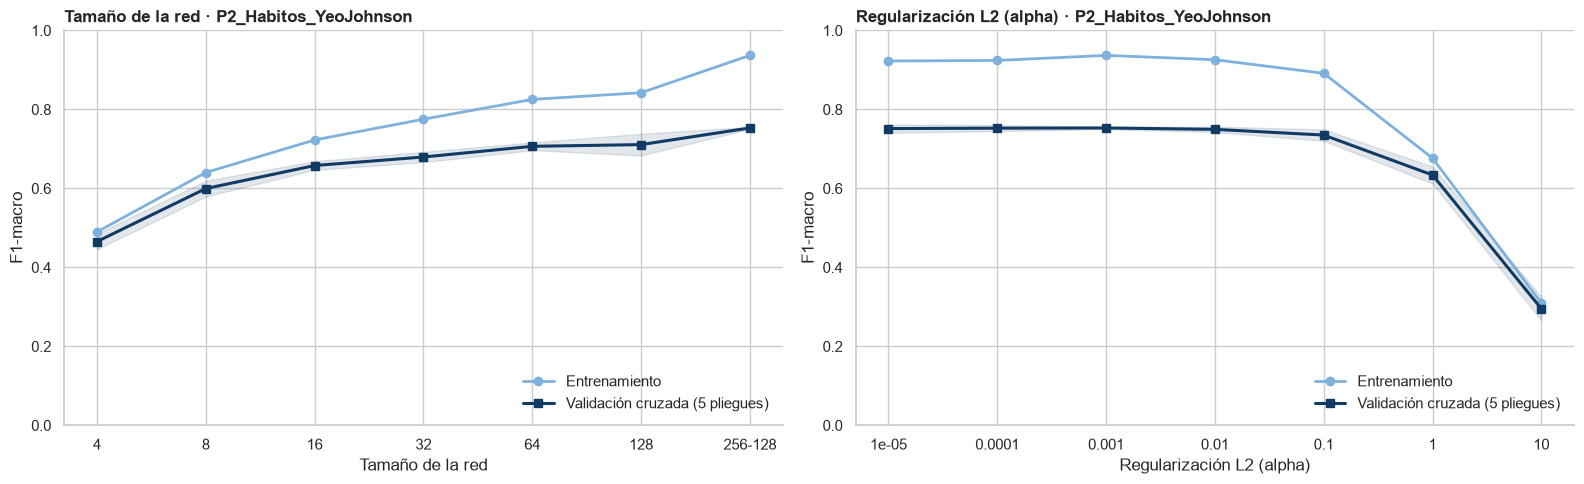

In [7]:
pipe_mejor = modelos_mlp[MEJOR_PREP]

arquitecturas = [(4,), (8,), (16,), (32,), (64,), (128,), (256, 128)]
alphas = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]


def curva(parametro, valores):
    rango = np.empty(len(valores), dtype=object)
    rango[:] = valores
    tr, val = validation_curve(
        clone(pipe_mejor), X_train, y_train, param_name=parametro, param_range=rango,
        cv=cv_5, scoring="f1_macro", n_jobs=-1,
    )
    return tr.mean(axis=1), val.mean(axis=1), val.std(axis=1)


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (parametro, valores, titulo, etiquetas_x) in zip(axes, [
    ("clf__hidden_layer_sizes", arquitecturas, "Tamaño de la red",
     ["-".join(map(str, a)) for a in arquitecturas]),
    ("clf__alpha", alphas, "Regularización L2 (alpha)", [f"{a:g}" for a in alphas]),
]):
    tr_m, val_m, val_s = curva(parametro, valores)
    x = np.arange(len(valores))
    ax.plot(x, tr_m, marker="o", color="#7fb1de", lw=2, label="Entrenamiento")
    ax.plot(x, val_m, marker="s", color="#123b63", lw=2.2, label="Validación cruzada (5 pliegues)")
    ax.fill_between(x, val_m - val_s, val_m + val_s, color="#123b63", alpha=0.12)
    ax.set_xticks(x, etiquetas_x)
    ax.set_xlabel(titulo)
    ax.set_ylabel("F1-macro")
    ax.set_ylim(0, 1)
    ax.set_title(f"{titulo} · {MEJOR_PREP}", fontweight="bold", loc="left")
    ax.legend(frameon=False, loc="lower right")
    ax.spines[["top", "right"]].set_visible(False)
    print(titulo)
    print(pd.DataFrame({"valor": etiquetas_x, "train": tr_m.round(3), "validación": val_m.round(3)}).to_string(index=False))
plt.tight_layout()
plt.show()

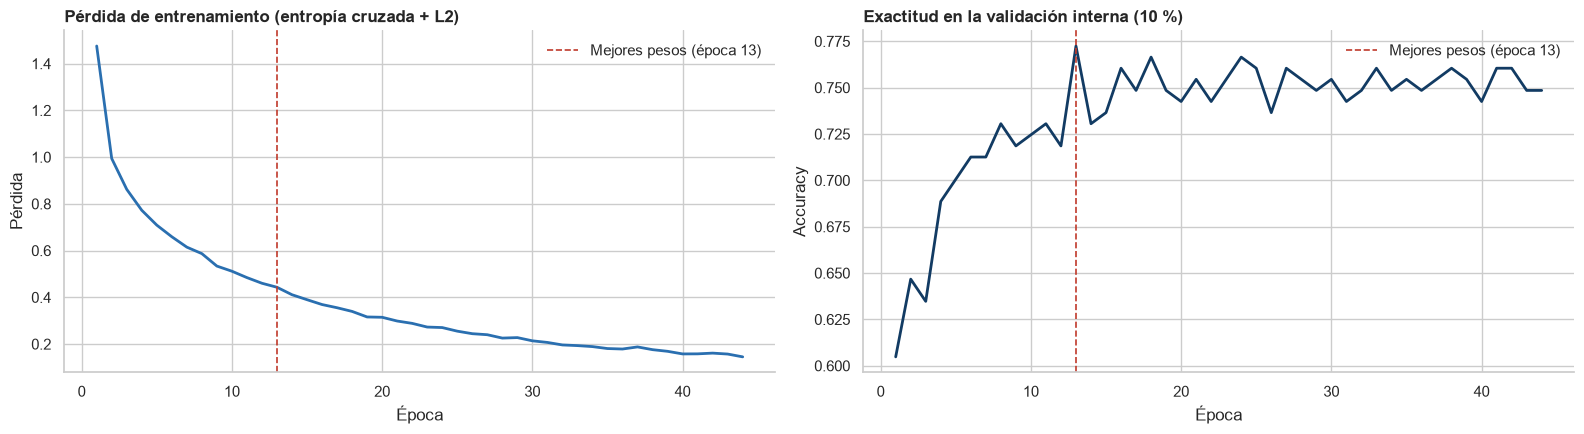

Épocas ejecutadas: 44 de 1000 | mejor época: 13 | accuracy de validación interna: 0.772


In [8]:
mlp = pipe_mejor.named_steps["clf"]
epocas = np.arange(1, mlp.n_iter_ + 1)
mejor_epoca = int(np.argmax(mlp.validation_scores_)) + 1

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(epocas, mlp.loss_curve_, color="#2a6fb0", lw=2)
axes[0].set_title("Pérdida de entrenamiento (entropía cruzada + L2)", fontweight="bold", loc="left")
axes[0].set_ylabel("Pérdida")
axes[1].plot(epocas, mlp.validation_scores_, color="#123b63", lw=2)
axes[1].set_title("Exactitud en la validación interna (10 %)", fontweight="bold", loc="left")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.axvline(mejor_epoca, color="#c0392b", ls="--", lw=1.2, label=f"Mejores pesos (época {mejor_epoca})")
    ax.set_xlabel("Época")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Épocas ejecutadas: {mlp.n_iter_} de {mlp.max_iter} | mejor época: {mejor_epoca} "
      f"| accuracy de validación interna: {mlp.best_validation_score_:.3f}")

## 7. Controles: sin `Gender` y benchmark operativo

Igual que en M1:

1. **Sin `Gender`:** mide cuánto depende el modelo de una variable sesgada por el sobremuestreo sintético (Obesidad II casi solo hombres, Obesidad III casi solo mujeres). Se usa el mejor preprocesamiento.
2. **Operativo:** incluye `Weight`, `Height` e `IMC` para cuantificar la fuga. Se usa P1, porque P2 rechaza esas variables por diseño.

Cada control repite la búsqueda de hiperparámetros.

In [9]:
modelo_sin_gender, res_sin_gender, _ = entrenar_evaluar_mlp(
    MEJOR_PREP, preprocesadores[MEJOR_PREP],
    X_train.drop(columns=["Gender"]), y_train, X_test.drop(columns=["Gender"]), y_test,
    nombre_bench="Preventivo (sin Gender)",
)

modelo_oper, res_oper, _ = entrenar_evaluar_mlp(
    "P1_RobustScaler", crear_preprocesador_p1,
    X_train_oper, y_train, X_test_oper, y_test,
    nombre_bench="Operativo (con Peso/Altura/IMC)",
)

fila_mejor = next(f for f in resultados_mlp if f["Preprocesamiento"] == MEJOR_PREP)
comparacion_controles = pd.DataFrame([fila_mejor, res_sin_gender, res_oper])
comparacion_controles.drop(columns=["Mejores hiperparámetros"]).set_index("Benchmark").T

Benchmark,Preventivo,Preventivo (sin Gender),Operativo (con Peso/Altura/IMC)
Modelo,M3_MLP,M3_MLP,M3_MLP
Preprocesamiento,P2_Habitos_YeoJohnson,P2_Habitos_YeoJohnson,P1_RobustScaler
CV F1-macro,0.7531 ± 0.0027,0.7120 ± 0.0117,0.9642 ± 0.0068
Train Accuracy,0.860,0.928,0.995
Test Accuracy,0.756,0.727,0.959
Brecha Train-Test,0.104,0.201,0.035
Test F1-macro,0.752,0.722,0.959
Tiempo fit (s),13.846,38.437,15.887
Latencia test (ms),24.967,25.696,13.618
ms / muestra,0.060,0.061,0.033


## 8. Evaluación del mejor modelo (benchmark preventivo)

=== Reporte por clase · M3 MLP + P2_Habitos_YeoJohnson (Preventivo) ===

              precision    recall  f1-score   support

 Peso insuf.      0.900     0.849     0.874        53
      Normal      0.596     0.596     0.596        57
 Sobrepeso I      0.627     0.673     0.649        55
Sobrepeso II      0.660     0.569     0.611        58
  Obesidad I      0.716     0.686     0.701        70
 Obesidad II      0.789     0.933     0.855        60
Obesidad III      0.984     0.969     0.977        65

    accuracy                          0.756       418
   macro avg      0.753     0.754     0.752       418
weighted avg      0.756     0.756     0.754       418



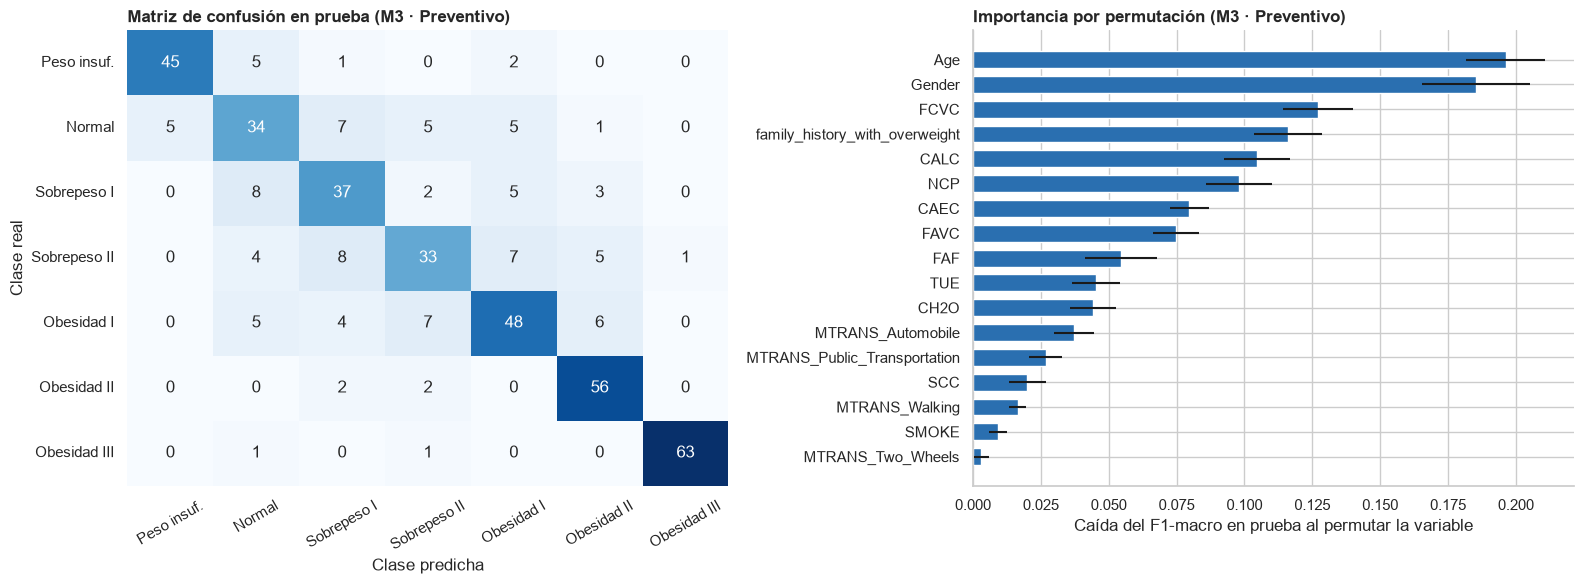

,media,desv
Age,0.196,0.015
Gender,0.185,0.020
FCVC,0.127,0.013
family_history_with_overweight,0.116,0.012
CALC,0.105,0.012
NCP,0.098,0.012
CAEC,0.080,0.007
FAVC,0.075,0.009
FAF,0.054,0.013
TUE,0.045,0.009


In [10]:
y_pred = pipe_mejor.predict(X_test)
etiquetas_cortas = ["Peso insuf.", "Normal", "Sobrepeso I", "Sobrepeso II",
                    "Obesidad I", "Obesidad II", "Obesidad III"]

print(f"=== Reporte por clase · M3 MLP + {MEJOR_PREP} (Preventivo) ===\n")
print(classification_report(y_test, y_pred, target_names=etiquetas_cortas, digits=3))

# Importancia por permutación: cuánto cae el F1-macro al desordenar cada variable original
importancia = permutation_importance(
    pipe_mejor, X_test, y_test, scoring="f1_macro", n_repeats=20, random_state=SEMILLA, n_jobs=-1)
imp = pd.DataFrame({"media": importancia.importances_mean, "desv": importancia.importances_std},
                   index=X_test.columns).sort_values("media")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=etiquetas_cortas, yticklabels=etiquetas_cortas, ax=axes[0])
axes[0].set_title("Matriz de confusión en prueba (M3 · Preventivo)", fontweight="bold", loc="left")
axes[0].set_xlabel("Clase predicha")
axes[0].set_ylabel("Clase real")
axes[0].tick_params(axis="x", rotation=30)
axes[0].tick_params(axis="y", rotation=0)

axes[1].barh(imp.index, imp["media"], xerr=imp["desv"], color="#2a6fb0", height=0.68)
axes[1].set_xlabel("Caída del F1-macro en prueba al permutar la variable")
axes[1].set_title("Importancia por permutación (M3 · Preventivo)", fontweight="bold", loc="left")
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

imp.sort_values("media", ascending=False)

## 9. Estabilidad ante la semilla

La inicialización de los pesos y el orden de los mini-lotes son aleatorios. Se reentrena el mejor modelo con 10 semillas (mismos hiperparámetros) para saber cuánto del resultado depende del azar.

In [11]:
filas_semillas = []
for semilla in [SEMILLA] + list(range(9)):
    p = clone(pipe_mejor).set_params(clf__random_state=semilla).fit(X_train, y_train)
    pred = p.predict(X_test)
    filas_semillas.append({"semilla": semilla,
                           "Test F1-macro": f1_score(y_test, pred, average="macro"),
                           "Test Accuracy": accuracy_score(y_test, pred),
                           "Épocas": p.named_steps["clf"].n_iter_})
semillas = pd.DataFrame(filas_semillas).set_index("semilla")
resumen_semillas = semillas.agg(["mean", "std", "min", "max"])
print(semillas.to_string())
resumen_semillas

         Test F1-macro  Test Accuracy  Épocas
semilla                                      
20               0.752          0.756      44
0                0.767          0.770      50
1                0.747          0.758      56
2                0.744          0.751      47
3                0.759          0.763     108
4                0.770          0.770      85
5                0.775          0.780      63
6                0.754          0.763      59
7                0.777          0.782      61
8                0.745          0.749      69


,Test F1-macro,Test Accuracy,Épocas
mean,0.759,0.764,64.200
std,0.012,0.011,19.395
min,0.744,0.749,44.000
max,0.777,0.782,108.000


## 10. Exportación de modelos y métricas

Se guardan los *pipelines* (`.pkl`), la tabla comparativa (`.csv`) y los metadatos (`m3_mlp_metricas.json`) en la misma carpeta y con el mismo esquema que M1.

> Para cargar un `.pkl` que use P2, la carpeta `src/` debe estar disponible, porque el pipeline llama a funciones de `src/p2_habitos.py`. Conviene cargarlo con la misma versión de scikit-learn que se usó para guardarlo.

In [12]:
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    CARPETA_MODELOS = Path("/content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos")
except ImportError:
    CARPETA_MODELOS = Path("modelos")

CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

# 1. Pipelines entrenados
for clave, pipe_ent in modelos_mlp.items():
    ruta = CARPETA_MODELOS / f"m3_mlp_{clave.lower()}_preventivo.pkl"
    joblib.dump(pipe_ent, ruta)
    print(f"Guardado: {ruta} ({ruta.stat().st_size / 1024:.1f} KB)")
ruta = CARPETA_MODELOS / "m3_mlp_sin_gender.pkl"
joblib.dump(modelo_sin_gender, ruta)
print(f"Guardado: {ruta} ({ruta.stat().st_size / 1024:.1f} KB)")

# 2. Tabla comparativa para consolidar con M1 y M2
tabla_export = pd.concat([tabla_mlp, comparacion_controles.iloc[1:]], ignore_index=True)
tabla_export["Mejores hiperparámetros"] = tabla_export["Mejores hiperparámetros"].apply(
    lambda d: json.dumps(d, ensure_ascii=False))
tabla_export.to_csv(CARPETA_MODELOS / "resultados_m3_mlp.csv", index=False, encoding="utf-8")

# 3. Metadatos para la app de despliegue
metricas_export = {
    "algoritmo": "MLPClassifier (M3)",
    "preprocesamiento": MEJOR_PREP,
    "benchmark": fila_mejor["Benchmark"],
    "accuracy": float(fila_mejor["Test Accuracy"]),
    "f1_macro": float(fila_mejor["Test F1-macro"]),
    "cv_f1_macro": fila_mejor["CV F1-macro"],
    "tiempo_fit_s": float(fila_mejor["Tiempo fit (s)"]),
    "ms_por_muestra": float(fila_mejor["ms / muestra"]),
    "tamano_kb": float(fila_mejor["Tamaño (.pkl KB)"]),
    "parametros": fila_mejor["Parámetros (W)"],
    "hiperparametros": fila_mejor["Mejores hiperparámetros"],
    "columnas": list(X_train.columns),
    "clases": {str(k): v for k, v in nombres_clases.items()},
    "rangos": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in X_train.columns},
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
}
(CARPETA_MODELOS / "m3_mlp_metricas.json").write_text(
    json.dumps(metricas_export, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Tabla CSV y metadatos JSON guardados en: {CARPETA_MODELOS}")

Guardado: modelos\m3_mlp_p1_robustscaler_preventivo.pkl (911.1 KB)
Guardado: modelos\m3_mlp_p2_habitos_yeojohnson_preventivo.pkl (937.2 KB)


Guardado: modelos\m3_mlp_sin_gender.pkl (932.4 KB)
Tabla CSV y metadatos JSON guardados en: modelos


## 11. Conclusiones de M3

**1. El ajuste de hiperparámetros pesa más que el preprocesamiento.**
Con la configuración usada de forma orientativa en `P2_habitos.ipynb`, el MLP obtenía 0,509 (P1) y 0,565 (P2) de F1-macro en validación cruzada. Después de la búsqueda sube a **0,742 (P1)** y **0,753 (P2)**. La mejor combinación fue la misma con ambos: capas (256, 128), `learning_rate_init` = 0,001, lotes de 32 y `alpha` = 0,001.

**2. P2 se elige por validación cruzada, pero su ventaja sobre P1 es pequeña.**

| | CV F1-macro | Test F1-macro | Test Accuracy | Brecha Train-Test | Épocas |
|---|:---:|:---:|:---:|:---:|:---:|
| P1 | 0,7421 ± 0,0134 | 0,756 | 0,766 | 0,161 | 72 |
| **P2** | **0,7531 ± 0,0027** | 0,752 | 0,756 | 0,104 | 44 |

- P2 supera a P1 en 1,1 puntos de media y gana en 3 de los 5 pliegues. En prueba, P1 queda 0,5 puntos arriba. Son diferencias del mismo orden que la variación por la semilla (±0,012), así que **no se puede afirmar que P2 clasifique mejor**.
- Lo que sí se observa es que P2 es **más estable entre pliegues** (desviación 0,003 frente a 0,013) y que, en este entrenamiento, deja una brecha menor entre entrenamiento y prueba.

**3. Control del sobreajuste.**
- La capacidad de la red manda: con 4 neuronas hay subajuste (0,47 en validación) y el rendimiento sube hasta (256, 128). En una comprobación aparte con validación cruzada, las redes (512, 256) y (256, 128, 64) no la superaron (0,739 ambas).
- `alpha` casi no cambia el resultado entre 1e-5 y 0,01. A partir de 0,1 empieza el subajuste y con 10 el modelo colapsa (0,30). La regularización L2 no cierra la brecha entre entrenamiento y validación sin perder rendimiento.
- Con *early stopping*, el modelo final se detuvo en la época 44 y recuperó los pesos de la época 13. La validación interna tiene unas 167 muestras, por lo que su curva es ruidosa y la época elegida tiene incertidumbre.

**4. Errores por clase.**
Los extremos se reconocen bien (Obesidad III 0,98, Peso insuficiente 0,87 y Obesidad II 0,86 de F1). Las confusiones se concentran en las clases intermedias: Normal (0,60), Sobrepeso II (0,61), Sobrepeso I (0,65) y Obesidad I (0,70).

**5. Sesgo de `Gender`.**
Es la segunda variable más importante por permutación (0,185), apenas por debajo de `Age` (0,196). Al quitarla, el F1-macro baja de 0,753 a 0,712 en validación cruzada y de 0,752 a 0,722 en prueba. Parte de ese aporte viene del sesgo sintético en Obesidad II y III, así que estas métricas deben reportarse con esa advertencia.

**6. Fuga de información.**
Con `Weight`, `Height` e `IMC`, el F1-macro en prueba pasa de 0,756 a **0,959** (ambos con P1). El benchmark operativo mide en gran parte la capacidad de recalcular el IMC, por lo que solo sirve como referencia.

**7. Complejidad.**
- El modelo con P2 tiene **39.431 parámetros**: unos 308 KB de pesos en `float64`.
- El `.pkl` pesa 937 KB porque también guarda el estado del optimizador Adam. Al eliminarlo queda en unos 320 KB con las mismas predicciones.
- La mayor latencia con P2 (0,060 frente a 0,015 ms por muestra) viene del preprocesamiento, no de la red. En una medición aparte con 50 repeticiones sobre las 418 filas de prueba, P2 tardó cerca de 20 ms en transformar (P1, cerca de 4 ms) y la red unos 3–4 ms en ambos casos.

**8. Comparación con M1 (mismas filas, P1).**

| Modelo + P1 | CV F1-macro | Test F1-macro | Brecha Train-Test | Tamaño `.pkl` |
|---|:---:|:---:|:---:|:---:|
| M1 Random Forest (`p1-m1-random-forest.ipynb`) | 0,775 | 0,782 | 0,100 | 9.956 KB |
| M3 MLP | 0,742 | 0,756 | 0,161 | 911 KB |

Random Forest obtiene unos 3 puntos más de F1-macro. El MLP ocupa cerca de 11 veces menos en disco. Los tiempos no se comparan aquí porque cada cuaderno se ejecutó en un equipo distinto.

**Limitaciones y pendientes**
- Falta integrar **P3** (una línea en el diccionario `preprocesadores`) y consolidar la matriz 3×3 con M2.
- La puntuación de validación cruzada de la mejor combinación es algo optimista, porque se eligió con ella. La prueba es la estimación final, y son solo 418 filas.
- Cerca del 77 % del dataset es sintético (SMOTE), así que las filas de prueba pueden parecerse a las de entrenamiento.
- Los tiempos y el tamaño deben medirse para los tres modelos en un mismo equipo antes de reportarlos en el artículo.